# Clasificador conjunto de intención y ranuras

**Proyecto SI-TBot Reservas** · Sistemas Inteligentes · Universidad de Ibagué · Daniel Vanegas

Este cuaderno entrena el componente del agente que entiende los mensajes. Recibe un texto como «¿me agenda un corte con Camilo mañana tipo tres?» y devuelve la intención (`reservar`) y las ranuras (servicio, barbero, fecha y hora). Sigo el enfoque del informe:

1. Parto de BETO y le añado dos salidas: una clasifica la intención desde el vector que resume el mensaje y otra asigna a cada palabra una etiqueta de ranura en formato BIO.
2. Hago un ajuste previo con el español de MASSIVE, que no trata de reservas pero enseña al modelo a marcar expresiones de tiempo.
3. Ajusto con mi corpus de 2 600 mensajes de reserva en español colombiano.
4. Mido en el conjunto de prueba la exactitud de intención, el F1 de ranuras y la exactitud del mensaje completo, y comparo con XLM-R y con una versión destilada de BETO.

Esta es la segunda versión. La primera se entrenó con 2 000 mensajes; al probar el bot en Telegram aparecieron mensajes que no entendía: un número que describía el corte («el 7 con desvanecido») leído como fecha, correcciones como «no bro, la cita es para el 16» y respuestas como «cualquiera». El corpus creció con esas formas de hablar y la prueba ahora incluye los mensajes reales que fallaron.

## 1. Preparación

In [1]:
import json, logging, math, random, re, tarfile, time, urllib.request, warnings, zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as avisos
from huggingface_hub.utils import disable_progress_bars

# Sin barras de descarga ni avisos de carga: solo quedan los resultados
avisos.set_verbosity_error(); avisos.disable_progress_bar(); disable_progress_bars()
logging.getLogger("huggingface_hub").setLevel(logging.ERROR); warnings.filterwarnings("ignore")

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "|", torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "CPU")

PyTorch 2.11.0+cu130 | Tesla T4


## 2. El corpus

El corpus sale de `corpus/construir.py` y llega aquí como `corpus_barberia.zip`, con tres archivos: entrenamiento, validación y prueba. Cada mensaje trae sus palabras y una etiqueta BIO por palabra. La prueba se apartó desde el principio y ninguno de sus mensajes se repite en las otras dos partes.

La prueba tiene tres bloques, que reporto por separado: los 300 mensajes de la primera versión, 16 mensajes reales que se le escribieron al bot en Telegram durante las pruebas y 54 nuevos con registro colombiano («oe parce», «sisas», «le caigo mañana»), descripciones del corte y correcciones.

In [2]:
if not Path("corpus_barberia.zip").exists():
    from google.colab import files
    files.upload()

with zipfile.ZipFile("corpus_barberia.zip") as z:
    z.extractall("corpus")

def leer(ruta):
    return [json.loads(linea) for linea in open(ruta, encoding="utf-8")]

train, val, test = (leer(f"corpus/{parte}.jsonl") for parte in ("train", "val", "test"))

INTENCIONES = ["reservar", "reprogramar", "cancelar", "consultar_disponibilidad", "consultar_servicios",
               "consultar_citas", "afirmar", "negar", "fuera_de_alcance"]
RANURAS = ["servicio", "barbero", "fecha", "hora", "franja", "nombre"]
ETIQUETAS = ["O"] + [f"{p}-{r}" for r in RANURAS for p in ("B", "I")]

conteo = pd.DataFrame({nombre: Counter(e["intencion"] for e in parte)
                       for nombre, parte in [("train", train), ("val", val), ("test", test)]}).loc[INTENCIONES]
conteo.loc["Total"] = conteo.sum()
display(conteo)
print("Bloques de la prueba:", dict(Counter(e["grupo"] for e in test)))

,train,val,test
reservar,590,102,118
reprogramar,220,38,42
cancelar,177,31,32
consultar_disponibilidad,243,42,45
consultar_servicios,177,31,32
consultar_citas,132,23,25
afirmar,118,20,22
negar,103,18,19
fuera_de_alcance,141,24,35
Total,1901,329,370


Bloques de la prueba: {'base': 300, 'reales': 16, 'colombiano': 54}


In [3]:
for e in random.Random(1).sample(train, 6):
    print(f"{e['intencion']:<26}", " ".join(t if y == "O" else f"{t}/{y}" for t, y in zip(e["tokens"], e["etiquetas"])))

consultar_servicios        qué más . ¿ cuánto se demora la barba/B-servicio ? muchas gracias
fuera_de_alcance           tienen parqueadero para moto
cancelar                   tengo cita el/B-fecha lunes/I-fecha por/B-hora ahi/I-hora a/I-hora las/I-hora once/I-hora y/I-hora media/I-hora pero ya no voy a ir
reprogramar                usted me puede reprogramar la cita ? es que me cambiaron el horario de clases
reprogramar                mi cita de mañana/B-fecha mejor que sea hoy/B-fecha si hay cupo
reservar                   hola hermano . me puedes agendar la barba/B-servicio con felipe/B-barbero ?


El tokenizador y el formato con corchetes son los mismos del corpus (`corpus/esquema.py`). Los repito aquí porque también sirven para leer MASSIVE y para que el agente separe las palabras igual que en el entrenamiento.

In [4]:
_TOKEN = re.compile(r"\d+[:/.]\d+(?:[:/.]\d+)?|[ap]\.\s?m\.|\w+|[^\w\s]", re.I)
_RANURA = re.compile(r"\[(\w+) : ([^\[\]]+)\]")

def tokenizar(texto):
    """[(palabra, inicio, fin)]. Horas (3:30) y fechas (15/10) quedan en una sola palabra."""
    return [(m.group(), m.start(), m.end()) for m in _TOKEN.finditer(texto)]

def leer_anotado(anotado):
    """'un [servicio : corte] [fecha : mañana]' -> ('un corte mañana', ranuras con posiciones)."""
    texto, ranuras, pos = "", [], 0
    for m in _RANURA.finditer(anotado):
        texto += anotado[pos:m.start()]
        ranuras.append({"tipo": m.group(1), "inicio": len(texto), "fin": len(texto) + len(m.group(2))})
        texto += m.group(2)
        pos = m.end()
    return texto + anotado[pos:], ranuras

def a_bio(texto, ranuras):
    palabras = tokenizar(texto)
    etiquetas = ["O"] * len(palabras)
    for r in ranuras:
        dentro = [i for i, (_, a, b) in enumerate(palabras) if a >= r["inicio"] and b <= r["fin"]]
        for k, i in enumerate(dentro):
            etiquetas[i] = ("I-" if k else "B-") + r["tipo"]
    return [p for p, _, _ in palabras], etiquetas

def tramos(etiquetas):
    """Etiquetas BIO -> {(tipo, primera palabra, última palabra + 1)}."""
    salida, inicio, tipo = set(), None, None
    for i, e in enumerate(list(etiquetas) + ["O"]):
        if tipo is not None and (e == "O" or e.startswith("B-") or e[2:] != tipo):
            salida.add((tipo, inicio, i))
            tipo = None
        if e != "O" and tipo is None:
            inicio, tipo = i, e[2:]
    return salida

a_bio(*leer_anotado("quiero un [servicio : corte] con [barbero : Camilo] [fecha : mañana] [hora : a las 3]"))

(['quiero', 'un', 'corte', 'con', 'Camilo', 'mañana', 'a', 'las', '3'],
 ['O',
  'O',
  'B-servicio',
  'O',
  'B-barbero',
  'B-fecha',
  'B-hora',
  'I-hora',
  'I-hora'])

## 3. MASSIVE en español

MASSIVE trae 16 521 órdenes a un asistente virtual en español de España, con 60 intenciones y 55 ranuras. Lo uso de dos maneras:

- **Ajuste previo.** Entreno primero el codificador con todo MASSIVE, para que llegue a mi corpus sabiendo marcar fechas, horas y nombres en español.
- **Ejemplos fuera de alcance.** Las frases de los dominios que no son de calendario, alarmas ni fecha y hora («pon música», «¿qué tiempo hace?») son mensajes que un bot de barbería no debe atender. Añado 300 al entrenamiento y 50 a la validación, y guardo otras 300 de la partición de prueba de MASSIVE para medir cuántas reconoce el modelo.

In [5]:
URL_MASSIVE = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
if not Path("massive.tar.gz").exists():
    urllib.request.urlretrieve(URL_MASSIVE, "massive.tar.gz")
with tarfile.open("massive.tar.gz") as t:
    filas = [json.loads(linea) for linea in t.extractfile("1.1/data/es-ES.jsonl").read().decode("utf-8").splitlines()]

massive = {"train": [], "dev": [], "test": []}
for f in filas:
    tokens, etiquetas = a_bio(*leer_anotado(f["annot_utt"]))
    massive[f["partition"]].append({"texto": f["utt"], "intencion": f["intent"], "dominio": f["scenario"],
                                    "tokens": tokens, "etiquetas": etiquetas})

INTENCIONES_M = sorted({m["intencion"] for m in massive["train"]})
RANURAS_M = sorted({e[2:] for m in massive["train"] for e in m["etiquetas"] if e != "O"})
ETIQUETAS_M = ["O"] + [f"{p}-{r}" for r in RANURAS_M for p in ("B", "I")]
print({k: len(v) for k, v in massive.items()}, "|", len(INTENCIONES_M), "intenciones,", len(RANURAS_M), "ranuras")

def ajenos(parte, n, semilla=0):
    """Frases de MASSIVE de otros dominios, como ejemplos de fuera de alcance."""
    candidatos = [m for m in massive[parte] if m["dominio"] not in {"calendar", "alarm", "datetime"}]
    return [{"texto": m["texto"], "intencion": "fuera_de_alcance", "tokens": m["tokens"],
             "etiquetas": ["O"] * len(m["tokens"]), "origen": "massive"}
            for m in random.Random(semilla).sample(candidatos, n)]

train_total = train + ajenos("train", 300)
val_total = val + ajenos("dev", 50)
ajenos_test = ajenos("test", 300)
print(len(train_total), "mensajes de entrenamiento,", len(val_total), "de validación,", len(test), "de prueba")
print([m["texto"] for m in ajenos_test[:4]])

{'train': 11514, 'dev': 2033, 'test': 2974} | 60 intenciones, 55 ranuras
2201 mensajes de entrenamiento, 379 de validación, 370 de prueba
['lidera el camino al lugar', 'cuantas patas tiene un perro', 'necesito algo de rap', 'podrías jugar este programa para mí']


## 4. El modelo

Es el modelo conjunto de Chen *et al.*: un codificador preentrenado y dos capas lineales. La intención se predice desde el vector de `[CLS]` y cada etiqueta de ranura desde el vector de la primera pieza de cada palabra. Se entrena minimizando la suma de las dos entropías cruzadas.

Las medidas son las tres del informe:

- **Intención:** proporción de mensajes con la intención correcta.
- **F1 de ranuras:** una ranura cuenta como acierto solo si coinciden el tipo y las palabras exactas del tramo.
- **Mensaje completo:** proporción de mensajes con la intención y todas las ranuras correctas. Es la que más me importa, porque una sola ranura equivocada es una cita equivocada.

In [6]:
class ClasificadorConjunto(nn.Module):
    def __init__(self, nombre, n_intenciones, n_etiquetas):
        super().__init__()
        self.codificador = AutoModel.from_pretrained(nombre)
        oculto = self.codificador.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.intencion = nn.Linear(oculto, n_intenciones)
        self.ranuras = nn.Linear(oculto, n_etiquetas)

    def forward(self, input_ids, attention_mask):
        h = self.dropout(self.codificador(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state)
        return self.intencion(h[:, 0]), self.ranuras(h)


def codificar(ejemplos, tok, intenciones, etiquetas):
    """Convierte los mensajes en piezas del tokenizador. Solo la primera pieza de cada palabra lleva etiqueta."""
    id_int = {x: i for i, x in enumerate(intenciones)}
    id_et = {x: i for i, x in enumerate(etiquetas)}
    enc = tok([e["tokens"] for e in ejemplos], is_split_into_words=True, truncation=True, max_length=64)
    datos = []
    for i, e in enumerate(ejemplos):
        palabras, y, anterior = enc.word_ids(i), [], None
        for p in palabras:
            y.append(id_et[e["etiquetas"][p]] if p is not None and p != anterior else -100)
            anterior = p
        datos.append({"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i], "ranuras": y,
                      "intencion": id_int[e["intencion"]], "palabras": palabras, "n": len(e["tokens"])})
    return datos


def lotes(datos, tam, pad, rng=None):
    orden = list(range(len(datos)))
    if rng:
        rng.shuffle(orden)
    for i in range(0, len(orden), tam):
        grupo = [datos[j] for j in orden[i:i + tam]]
        largo = max(len(d["input_ids"]) for d in grupo)
        relleno = lambda clave, valor: torch.tensor([d[clave] + [valor] * (largo - len(d[clave])) for d in grupo])
        yield {"input_ids": relleno("input_ids", pad).to(DISPOSITIVO),
               "attention_mask": relleno("attention_mask", 0).to(DISPOSITIVO),
               "ranuras": relleno("ranuras", -100).to(DISPOSITIVO),
               "intencion": torch.tensor([d["intencion"] for d in grupo]).to(DISPOSITIVO)}, grupo


@torch.no_grad()
def predecir(modelo, datos, etiquetas, pad):
    modelo.eval()
    salida = []
    for lote, grupo in lotes(datos, 128, pad):
        log_int, log_ran = modelo(lote["input_ids"], lote["attention_mask"])
        prob, marcas = log_int.softmax(-1).cpu(), log_ran.argmax(-1).cpu()
        for k, d in enumerate(grupo):
            pred, anterior = ["O"] * d["n"], None
            for j, p in enumerate(d["palabras"]):
                if p is not None and p != anterior:
                    pred[p] = etiquetas[marcas[k, j]]
                anterior = p
            salida.append({"intencion": int(prob[k].argmax()), "confianza": float(prob[k].max()), "etiquetas": pred})
    return salida


def medir(ejemplos, pred, intenciones):
    vp = fp = fn = 0
    bien_int, completos = [], []
    for e, p in zip(ejemplos, pred):
        oro, hip = tramos(e["etiquetas"]), tramos(p["etiquetas"])
        vp, fp, fn = vp + len(oro & hip), fp + len(hip - oro), fn + len(oro - hip)
        bien_int.append(intenciones[p["intencion"]] == e["intencion"])
        completos.append(bien_int[-1] and oro == hip)
    precision, exhaustividad = vp / max(vp + fp, 1), vp / max(vp + fn, 1)
    f1 = 2 * precision * exhaustividad / max(precision + exhaustividad, 1e-9)
    return {"intención": float(np.mean(bien_int)), "F1 ranuras": f1, "mensaje completo": float(np.mean(completos))}


def entrenar(modelo, datos, pad, epocas, lr, semilla, validar=None, paciencia=3, tam=32):
    """Ajusta el modelo. Con `validar`, se queda con los pesos de la mejor época en mensaje completo."""
    rng = random.Random(semilla)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    total = epocas * math.ceil(len(datos) / tam)
    calentamiento = max(1, int(0.1 * total))
    plan = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / calentamiento if s < calentamiento else max(0.0, (total - s) / (total - calentamiento)))
    mejor, mejor_estado, sin_mejora, historia = -1.0, None, 0, []
    for epoca in range(1, epocas + 1):
        modelo.train()
        perdidas = []
        for lote, _ in lotes(datos, tam, pad, rng):
            log_int, log_ran = modelo(lote["input_ids"], lote["attention_mask"])
            perdida = (nn.functional.cross_entropy(log_int, lote["intencion"])
                       + nn.functional.cross_entropy(log_ran.flatten(0, 1), lote["ranuras"].flatten(), ignore_index=-100))
            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step(); plan.step(); opt.zero_grad()
            perdidas.append(perdida.item())
        fila = {"época": epoca, "pérdida": float(np.mean(perdidas))}
        if validar:
            fila.update(validar(modelo))
            if fila["mensaje completo"] > mejor:
                mejor, sin_mejora = fila["mensaje completo"], 0
                mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
        historia.append(fila)
        if validar and sin_mejora >= paciencia:
            break
    if mejor_estado:
        modelo.load_state_dict(mejor_estado)
    return pd.DataFrame(historia)


def fijar_semilla(semilla):
    random.seed(semilla); np.random.seed(semilla); torch.manual_seed(semilla); torch.cuda.manual_seed_all(semilla)

## 5. Ajuste previo con MASSIVE

Tres épocas sobre las 11 514 frases de entrenamiento de MASSIVE en español, con sus propias intenciones y ranuras. Al terminar mido en su partición de prueba, que es el punto de comparación con los valores publicados para este conjunto, y guardo solo el codificador: las dos capas de salida se descartan porque las etiquetas de MASSIVE no son las nuestras.

In [7]:
BETO = "dccuchile/bert-base-spanish-wwm-uncased"
tok_beto = AutoTokenizer.from_pretrained(BETO)

fijar_semilla(0)
inicio = time.time()
modelo = ClasificadorConjunto(BETO, len(INTENCIONES_M), len(ETIQUETAS_M)).to(DISPOSITIVO)
print(f"{sum(p.numel() for p in modelo.parameters()) / 1e6:.1f} millones de parámetros")
m_train = codificar(massive["train"], tok_beto, INTENCIONES_M, ETIQUETAS_M)
m_test = codificar(massive["test"], tok_beto, INTENCIONES_M, ETIQUETAS_M)
historia_massive = entrenar(modelo, m_train, tok_beto.pad_token_id, epocas=3, lr=5e-5, semilla=0)
en_massive = medir(massive["test"], predecir(modelo, m_test, ETIQUETAS_M, tok_beto.pad_token_id), INTENCIONES_M)
torch.save(modelo.codificador.state_dict(), "beto_massive.pt")
del modelo; torch.cuda.empty_cache()
print(f"{time.time() - inicio:.0f} s")
display(historia_massive.round(3))
print("MASSIVE es-ES, partición de prueba:", {k: round(100 * v, 1) for k, v in en_massive.items()})

110.0 millones de parámetros
185 s


,época,pérdida
0,1,3.039
1,2,1.046
2,3,0.652


MASSIVE es-ES, partición de prueba: {'intención': 86.0, 'F1 ranuras': 63.3, 'mensaje completo': 56.9}


Con tres épocas el codificador ya clasifica bien la intención de MASSIVE (86,0 %), pero se queda corto en las ranuras (F1 de 63,3 %). La pérdida seguía bajando cuando paré, así que no entrené hasta converger y estas cifras no son comparables con las publicadas. Para lo que busco es suficiente: me llevo un codificador que ya vio fechas, horas y nombres anotados en español. Las cifras son las mismas de la primera versión, porque este paso no depende de mi corpus.

## 6. Ajuste con el corpus propio

Entreno cuatro variantes con los mismos datos y el mismo procedimiento:

| Variante | Codificador | Ajuste previo |
|---|---|---|
| BETO + MASSIVE | BETO | Sí. Es el modelo propuesto. |
| BETO | BETO | No |
| DistilBETO | BETO destilado, con la mitad de las capas | No |
| XLM-R | XLM-RoBERTa base, multilingüe | No |

Cada una se entrena hasta 15 épocas y se queda con la época de mejor mensaje completo en validación. Como el conjunto de prueba es pequeño, repito cada variante con tres semillas y reporto el promedio y la desviación.

In [8]:
VARIANTES = {
    "BETO + MASSIVE": (BETO, True, 5e-5),
    "BETO": (BETO, False, 5e-5),
    "DistilBETO": ("dccuchile/distilbert-base-spanish-uncased", False, 5e-5),
    "XLM-R": ("FacebookAI/xlm-roberta-base", False, 3e-5),
}
SEMILLAS = [0, 1, 2]
PARTES = {"val": val_total, "test": test, "ajenos": ajenos_test}

resultados, corridas, mejor_propuesto = [], {}, {"val": -1}
for variante, (nombre, preajuste, lr) in VARIANTES.items():
    tok = AutoTokenizer.from_pretrained(nombre)
    pad = tok.pad_token_id
    d_train = codificar(train_total, tok, INTENCIONES, ETIQUETAS)
    d = {parte: codificar(ejemplos, tok, INTENCIONES, ETIQUETAS) for parte, ejemplos in PARTES.items()}
    for semilla in SEMILLAS:
        fijar_semilla(semilla)
        inicio = time.time()
        modelo = ClasificadorConjunto(nombre, len(INTENCIONES), len(ETIQUETAS))
        if preajuste:
            modelo.codificador.load_state_dict(torch.load("beto_massive.pt", weights_only=True))
        modelo.to(DISPOSITIVO)
        validar = lambda m: medir(val_total, predecir(m, d["val"], ETIQUETAS, pad), INTENCIONES)
        historia = entrenar(modelo, d_train, pad, epocas=15, lr=lr, semilla=semilla, validar=validar)
        pred = {parte: predecir(modelo, d[parte], ETIQUETAS, pad) for parte in PARTES}
        fila = {"variante": variante, "semilla": semilla, "épocas": len(historia), "segundos": round(time.time() - inicio),
                "parámetros (M)": round(sum(p.numel() for p in modelo.parameters()) / 1e6, 1)}
        for parte in ("val", "test"):
            fila.update({f"{parte} · {k}": v for k, v in medir(PARTES[parte], pred[parte], INTENCIONES).items()})
        fuera = INTENCIONES.index("fuera_de_alcance")
        propios = [p for e, p in zip(test, pred["test"]) if e["intencion"] == "fuera_de_alcance"]
        fila["fuera de alcance · corpus"] = float(np.mean([p["intencion"] == fuera for p in propios]))
        fila["fuera de alcance · MASSIVE"] = float(np.mean([p["intencion"] == fuera for p in pred["ajenos"]]))
        resultados.append(fila)
        corridas[variante, semilla] = {"historia": historia, "pred": pred}
        if preajuste and fila["val · mensaje completo"] > mejor_propuesto["val"]:
            mejor_propuesto = {"val": fila["val · mensaje completo"], "semilla": semilla,
                               "estado": {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}}
        print(f"{variante:<15} semilla {semilla}: {len(historia):>2} épocas, {fila['segundos']:>3} s | prueba: "
              f"intención {fila['test · intención']:.3f}, F1 {fila['test · F1 ranuras']:.3f}, "
              f"completo {fila['test · mensaje completo']:.3f}")
        del modelo; torch.cuda.empty_cache()

resultados = pd.DataFrame(resultados)

BETO + MASSIVE  semilla 0: 11 épocas, 162 s | prueba: intención 0.949, F1 0.967, completo 0.900
BETO + MASSIVE  semilla 1: 10 épocas, 146 s | prueba: intención 0.938, F1 0.950, completo 0.873
BETO + MASSIVE  semilla 2: 14 épocas, 204 s | prueba: intención 0.949, F1 0.960, completo 0.892
BETO            semilla 0: 13 épocas, 188 s | prueba: intención 0.957, F1 0.974, completo 0.914
BETO            semilla 1: 12 épocas, 174 s | prueba: intención 0.941, F1 0.962, completo 0.884
BETO            semilla 2: 13 épocas, 189 s | prueba: intención 0.957, F1 0.963, completo 0.900
DistilBETO      semilla 0: 12 épocas,  91 s | prueba: intención 0.946, F1 0.942, completo 0.865
DistilBETO      semilla 1: 10 épocas,  76 s | prueba: intención 0.943, F1 0.947, completo 0.873
DistilBETO      semilla 2: 14 épocas, 105 s | prueba: intención 0.949, F1 0.947, completo 0.873
XLM-R           semilla 0: 15 épocas, 314 s | prueba: intención 0.957, F1 0.977, completo 0.924
XLM-R           semilla 1: 15 épocas, 31

## 7. Resultados

In [9]:
medidas = [c for c in resultados.columns if "·" in c]
grupo = resultados.groupby("variante", sort=False)
tabla = (100 * grupo[medidas].mean()).round(1).astype(str) + " ± " + (100 * grupo[medidas].std()).round(1).astype(str)
tabla.insert(0, "parámetros (M)", grupo["parámetros (M)"].first())
tabla.insert(1, "segundos", grupo["segundos"].mean().round())
pd.set_option("display.max_columns", None, "display.width", 250)
display(tabla[["parámetros (M)", "segundos"] + [c for c in medidas if c.startswith("test")]])
display(tabla[[c for c in medidas if not c.startswith("test")]])

,parámetros (M),segundos,test · intención,test · F1 ranuras,test · mensaje completo
variante,,,,,
BETO + MASSIVE,109.9,171.0,94.5 ± 0.6,95.9 ± 0.9,88.8 ± 1.4
BETO,109.9,184.0,95.1 ± 0.9,96.7 ± 0.7,89.9 ± 1.5
DistilBETO,66.7,91.0,94.6 ± 0.3,94.5 ± 0.3,87.0 ± 0.5
XLM-R,278.1,307.0,96.3 ± 1.3,97.2 ± 0.5,92.6 ± 1.4


,val · intención,val · F1 ranuras,val · mensaje completo,fuera de alcance · corpus,fuera de alcance · MASSIVE
variante,,,,,
BETO + MASSIVE,94.0 ± 0.5,97.2 ± 0.6,90.5 ± 0.5,98.1 ± 3.3,98.4 ± 0.4
BETO,92.6 ± 1.2,95.9 ± 0.4,88.2 ± 1.0,96.2 ± 1.6,96.4 ± 0.7
DistilBETO,93.1 ± 0.3,95.3 ± 0.5,88.0 ± 0.7,92.4 ± 5.9,97.2 ± 0.8
XLM-R,94.4 ± 0.7,96.5 ± 1.0,90.5 ± 1.1,88.6 ± 5.7,96.9 ± 0.8


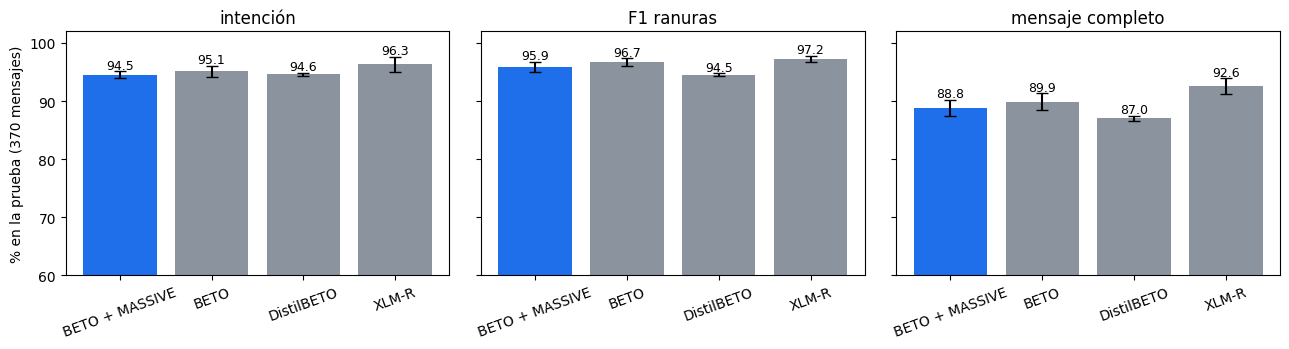

In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for eje, medida in zip(ejes, ["intención", "F1 ranuras", "mensaje completo"]):
    medias, desv = 100 * grupo[f"test · {medida}"].mean(), 100 * grupo[f"test · {medida}"].std()
    eje.bar(medias.index, medias, yerr=desv, capsize=4, color=["#1f6feb", "#8b949e", "#8b949e", "#8b949e"])
    for i, v in enumerate(medias):
        eje.text(i, v + desv.iloc[i] + 0.4, f"{v:.1f}", ha="center", fontsize=9)
    eje.set_title(medida); eje.set_ylim(60, 102); eje.tick_params(axis="x", labelrotation=20)
ejes[0].set_ylabel(f"% en la prueba ({len(test)} mensajes)")
plt.tight_layout(); plt.show()

- **El modelo propuesto** acierta la intención en el 94,5 % de los 370 mensajes de prueba, las ranuras con un F1 de 95,9 % y el mensaje completo en el 88,8 %. Cerca de uno de cada diez mensajes llega a la política con algo equivocado, y por eso la confirmación antes de escribir en la agenda sigue siendo obligatoria.
- **El ajuste previo con MASSIVE** no ayuda en la prueba esta vez: BETO sin él llega a 89,9 %. Sí ayuda en validación (90,5 % frente a 88,2 %) y con los mensajes fuera de alcance del corpus (98,1 % frente a 96,2 %). Las diferencias caben en la variación entre semillas (±1,4 y ±1,5), así que con estas cifras no se puede decir que una de las dos variantes de BETO sea mejor.
- **DistilBETO** pierde cerca de dos puntos de mensaje completo a cambio de entrenar en la mitad del tiempo con el 60 % de los parámetros.
- **XLM-R** vuelve a quedar arriba, con 92,6 %. Es 2,5 veces más grande y tarda casi el doble en entrenar. Mantengo BETO, que es el modelo del diseño y el que ya corre en el computador del agente; XLM-R queda como la alternativa más clara si hace falta subir la exactitud.
- **Fuera de alcance.** El modelo propuesto reconoce el 98,1 % de los mensajes ajenos del corpus y el 98,4 % de las 300 frases de MASSIVE que no había visto.

Estas cifras siguen siendo optimistas: casi toda la prueba la escribió el mismo LLM que redactó parte del entrenamiento. Sirven para comparar las variantes entre sí.

### Por bloque de la prueba

El promedio de toda la prueba esconde lo que más interesa en esta versión: cómo le va a cada variante con los mensajes reales y con el registro colombiano.

In [11]:
filas = []
for (variante, s), c in corridas.items():
    for bloque in ["base", "reales", "colombiano"]:
        idx = [i for i, e in enumerate(test) if e["grupo"] == bloque]
        m = medir([test[i] for i in idx], [c["pred"]["test"][i] for i in idx], INTENCIONES)
        filas.append({"variante": variante, "bloque": f"{bloque} ({len(idx)})", **m})
por_bloque = pd.DataFrame(filas).groupby(["variante", "bloque"], sort=False)[["intención", "F1 ranuras", "mensaje completo"]].mean()
(100 * por_bloque).round(1).unstack("bloque")

intención                             F1 ranuras                             mensaje completo                            
bloque         base (300) reales (16) colombiano (54) base (300) reales (16) colombiano (54)       base (300) reales (16) colombiano (54)
variante                                                                                                                                 
BETO + MASSIVE       93.9       100.0            96.3       96.5        95.4            93.5             89.4        93.8            84.0
BETO                 94.2       100.0            98.8       96.8        98.7            95.5             89.4        97.9            90.1
DistilBETO           94.0        95.8            97.5       94.8        94.1            93.3             87.1        91.7            85.2
XLM-R                96.0       100.0            96.9       97.4       100.0            95.9             92.8       100.0            89.5

Con el corpus nuevo, el modelo entiende los mensajes que fallaron en Telegram. En promedio de las tres semillas, BETO + MASSIVE acierta el mensaje completo en el 93,8 % de los 16 mensajes reales y en el 84,0 % de los 54 de registro colombiano. El modelo que usaba el agente antes, la versión de 8 bits de la primera corrida, se quedaba en 68,8 % y 48,1 % en esos mismos bloques. En los 300 mensajes de la primera versión el promedio es el mismo de antes, 89,4 %, así que lo nuevo no se aprendió a costa de lo anterior.

En el bloque colombiano BETO sin ajuste previo sale mejor (90,1 %), pero con 54 mensajes cada uno vale casi dos puntos y la diferencia cabe en la variación entre semillas. Los 16 mensajes reales son todavía menos: cada uno vale seis puntos. Estas cifras dicen que esos casos ya no fallan, no cuánto acertaría el modelo con cualquier cliente.

### El modelo propuesto, intención por intención

Tomo la corrida de BETO + MASSIVE con mejor validación, que es la que guardo para el agente.

Semilla 2 | {'intención': 94.9, 'F1 ranuras': 96.0, 'mensaje completo': 89.2}
                          precision    recall  f1-score   support

                reservar      0.935     0.983     0.959       118
             reprogramar      1.000     0.881     0.937        42
                cancelar      0.970     1.000     0.985        32
consultar_disponibilidad      0.976     0.911     0.943        45
     consultar_servicios      1.000     0.969     0.984        32
         consultar_citas      0.960     0.960     0.960        25
                 afirmar      1.000     0.909     0.952        22
                   negar      1.000     0.789     0.882        19
        fuera_de_alcance      0.814     1.000     0.897        35

                accuracy                          0.949       370
               macro avg      0.962     0.934     0.944       370
            weighted avg      0.954     0.949     0.949       370



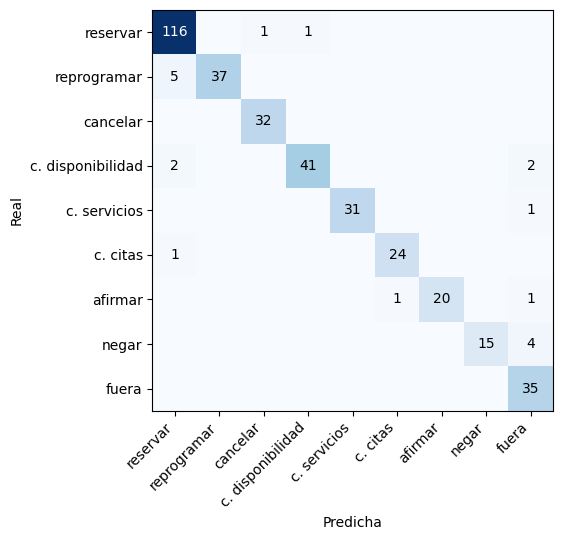

In [12]:
semilla = mejor_propuesto["semilla"]
pred_test = corridas["BETO + MASSIVE", semilla]["pred"]["test"]
oro = [e["intencion"] for e in test]
hip = [INTENCIONES[p["intencion"]] for p in pred_test]
print("Semilla", semilla, "|", {k: round(100 * v, 1) for k, v in medir(test, pred_test, INTENCIONES).items()})
print(classification_report(oro, hip, labels=INTENCIONES, digits=3, zero_division=0))

matriz = confusion_matrix(oro, hip, labels=INTENCIONES)
fig, eje = plt.subplots(figsize=(6.5, 5.5))
eje.imshow(matriz, cmap="Blues")
cortas = [i.replace("consultar_", "c. ").replace("fuera_de_alcance", "fuera") for i in INTENCIONES]
eje.set_xticks(range(9), cortas, rotation=45, ha="right"); eje.set_yticks(range(9), cortas)
for i in range(9):
    for j in range(9):
        if matriz[i, j]:
            eje.text(j, i, matriz[i, j], ha="center", va="center", color="white" if matriz[i, j] > matriz.max() / 2 else "black")
eje.set_xlabel("Predicha"); eje.set_ylabel("Real"); plt.tight_layout(); plt.show()

In [13]:
filas = []
for ranura in RANURAS:
    vp = fp = fn = 0
    for e, p in zip(test, pred_test):
        o = {t for t in tramos(e["etiquetas"]) if t[0] == ranura}
        h = {t for t in tramos(p["etiquetas"]) if t[0] == ranura}
        vp, fp, fn = vp + len(o & h), fp + len(h - o), fn + len(o - h)
    pr, ex = vp / max(vp + fp, 1), vp / max(vp + fn, 1)
    filas.append({"ranura": ranura, "precisión": pr, "exhaustividad": ex, "F1": 2 * pr * ex / max(pr + ex, 1e-9), "en la prueba": vp + fn})
pd.DataFrame(filas).set_index("ranura").round(3)

,precisión,exhaustividad,F1,en la prueba
ranura,,,,
servicio,0.913,0.905,0.909,105
barbero,0.957,0.957,0.957,46
fecha,0.980,0.980,0.980,200
hora,0.977,0.977,0.977,86
franja,0.955,1.000,0.977,42
nombre,0.875,0.875,0.875,8


In [14]:
def frase(e, etiquetas):
    return " ".join(t if y == "O" else f"[{t}/{y}]" for t, y in zip(e["tokens"], etiquetas))

errores = [(e, p) for e, p in zip(test, pred_test)
           if INTENCIONES[p["intencion"]] != e["intencion"] or tramos(p["etiquetas"]) != tramos(e["etiquetas"])]
print(len(errores), "mensajes de la prueba con algún error\n")
for e, p in errores:
    print(f"real:    {e['intencion']:<25} {frase(e, e['etiquetas'])}")
    print(f"predijo: {INTENCIONES[p['intencion']]:<25} {frase(e, p['etiquetas'])}   (confianza {p['confianza']:.2f})\n")

40 mensajes de la prueba con algún error

real:    reservar                  necesito [motilarme/B-servicio] [hoy/B-fecha] , tienen algo [tipo/B-hora] [5/I-hora] ?
predijo: consultar_disponibilidad  necesito [motilarme/B-servicio] [hoy/B-fecha] , tienen algo [tipo/B-hora] [5/I-hora] ?   (confianza 0.95)

real:    reservar                  ey bro agéndame [mañana/B-fecha] [temprano/B-franja] que tengo una entrevista
predijo: cancelar                  ey bro agéndame [mañana/B-fecha] [temprano/B-franja] que tengo una entrevista   (confianza 0.80)

real:    reservar                  me toca [motilarme/B-servicio] antes del grado , apártame [el/B-fecha] [viernes/I-fecha] [a/B-hora] [mediodía/I-hora]
predijo: reservar                  me toca [motilarme/B-servicio] [antes/B-franja] [del/I-franja] [grado/I-franja] , apártame [el/B-fecha] [viernes/I-fecha] [a/B-hora] [mediodía/I-hora]   (confianza 1.00)

real:    reservar                  quiero [lo/B-servicio] [de/I-servicio] [siempre/I-serv

El modelo guardado falla en 40 de los 370 mensajes: 19 con la intención equivocada y 21 con alguna ranura mal.

- **Fuera de alcance absorbe lo que el modelo no reconoce.** Ocho mensajes válidos terminaron en `fuera_de_alcance`, entre ellos «melo», «nanay», «nel pastel» y «cuál es el horario de atención». Es el error menos grave: el agente se los pasa al LLM de respaldo.
- **Cambiar una cita se lee como reservar.** Cinco mensajes que cambian una cita se leyeron como una reserva nueva («ya no con Andrés, pásame con Camilo»), la confusión entre intenciones vecinas que advierten Sahu *et al.* El resumen antes de confirmar deja ver que el agente entendió una cita nueva y no un cambio.
- **Ranuras.** Fecha, hora y franja quedan entre 97,7 % y 98,0 % de F1. Servicio sube a 90,9 % aunque ahora incluye las descripciones del corte; sus errores están en los bordes del tramo («rebajar un poquito los lados y la barba» quedó en un solo tramo, y son dos) o en lo que no describe la cita: en «tengo matrimonio el sábado, ¿me atiende el viernes en la tarde?» marcó también el sábado. Para ese caso la política no adivina: si un mensaje trae dos fechas distintas, pregunta cuál.

Casi todos los errores vienen con confianza alta, y eso condiciona la sección siguiente.

## 8. Confianza y paso al LLM

El agente solo confía en el clasificador cuando este está seguro; los demás mensajes pasan al LLM de respaldo. La tabla muestra, para distintos umbrales de confianza en la intención, qué parte de los mensajes atiende el clasificador y con qué exactitud. El umbral se elige en validación y se comprueba en la prueba.

In [15]:
pred_val = corridas["BETO + MASSIVE", semilla]["pred"]["val"]
filas = []
for umbral in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    fila = {"umbral": umbral}
    for nombre, ejemplos, pred in [("val", val_total, pred_val), ("test", test, pred_test)]:
        seguros = [(e, p) for e, p in zip(ejemplos, pred) if p["confianza"] >= umbral]
        fila[f"{nombre} · atiende"] = len(seguros) / len(ejemplos)
        fila[f"{nombre} · intención"] = float(np.mean([INTENCIONES[p["intencion"]] == e["intencion"] for e, p in seguros]))
        fila[f"{nombre} · mensaje completo"] = float(np.mean(
            [INTENCIONES[p["intencion"]] == e["intencion"] and tramos(p["etiquetas"]) == tramos(e["etiquetas"]) for e, p in seguros]))
    filas.append(fila)
(100 * pd.DataFrame(filas).set_index("umbral")).round(1)

,val · atiende,val · intención,val · mensaje completo,test · atiende,test · intención,test · mensaje completo
umbral,,,,,,
0.00,100.0,94.5,91.0,100.0,94.9,89.2
0.50,100.0,94.5,91.0,99.5,95.4,89.7
0.60,100.0,94.5,91.0,98.4,95.6,90.1
0.70,100.0,94.5,91.0,97.8,96.1,90.6
0.80,99.7,94.7,91.3,97.6,96.4,90.9
0.90,99.2,95.2,91.8,96.8,96.6,91.1
0.95,98.2,95.4,91.9,95.9,97.2,91.5
0.99,95.8,96.7,93.1,93.0,98.5,93.0


La confianza separa algo más que en la primera versión, pero poco. Con un umbral de 0,95 el clasificador se queda con el 95,9 % de los mensajes de prueba y su exactitud de intención sube de 94,9 % a 97,2 %; con 0,99 llega a 98,5 % y el 7 % de los mensajes pasa al LLM.

Mantengo 0,95, que en validación deja pasar el 98,2 % de los mensajes con 95,4 % de exactitud. El umbral no reemplaza la confirmación con botón, que es la que impide que un error llegue a la agenda.

## 9. El modelo que usa el agente

Tomo la corrida de BETO + MASSIVE con mejor validación. La función `entender` es la que aplica el agente a cada mensaje de Telegram: separa las palabras con el mismo tokenizador del corpus y devuelve la intención, la confianza y las ranuras con el texto tal como lo escribió el cliente. La fecha y la hora no se calculan aquí: esos tramos pasan después al normalizador de reglas.

In [16]:
modelo = ClasificadorConjunto(BETO, len(INTENCIONES), len(ETIQUETAS))
modelo.load_state_dict(mejor_propuesto["estado"])
modelo.to(DISPOSITIVO).eval()

Path("modelo_tbot").mkdir(exist_ok=True)
torch.save(modelo.state_dict(), "modelo_tbot/pesos.pt")
tok_beto.save_pretrained("modelo_tbot")
Path("modelo_tbot/esquema.json").write_text(
    json.dumps({"base": BETO, "intenciones": INTENCIONES, "etiquetas": ETIQUETAS}, ensure_ascii=False), encoding="utf-8")


@torch.no_grad()
def entender(texto):
    palabras = tokenizar(texto)
    if not palabras:
        return {"intencion": "fuera_de_alcance", "confianza": 1.0, "ranuras": []}
    enc = tok_beto([p for p, _, _ in palabras], is_split_into_words=True, truncation=True, max_length=64, return_tensors="pt")
    log_int, log_ran = modelo(enc["input_ids"].to(DISPOSITIVO), enc["attention_mask"].to(DISPOSITIVO))
    prob = log_int.softmax(-1)[0]
    etiquetas, anterior = ["O"] * len(palabras), None
    for j, p in enumerate(enc.word_ids(0)):
        if p is not None and p != anterior:
            etiquetas[p] = ETIQUETAS[int(log_ran[0, j].argmax())]
        anterior = p
    ranuras = [{"tipo": tipo, "valor": texto[palabras[a][1]:palabras[b - 1][2]]}
               for tipo, a, b in sorted(tramos(etiquetas), key=lambda t: t[1])]
    return {"intencion": INTENCIONES[int(prob.argmax())], "confianza": round(float(prob.max()), 3), "ranuras": ranuras}


for mensaje in ["¿Me agenda un corte con Camilo mañana tipo tres?", "cámbieme la del sábado para el lunes",
                "¿tiene cupo mañana en la tarde?", "¿venden cera para el pelo?", "ya no voy a poder ir el viernes",
                "cuanto vale la barba", "a q hora quede el sabado", "dale, de una", "pasado mañana a mediodía con el que esté libre",
                "oe bro estoy muy mechudo dame una cita para el 16 en la madrugada, quiero solo las puntas y el 7 con desvanecido.",
                "no bro la cita es para el 16", "cualquiera", "que barberos hay disponibles?", "sisas"]:
    r = entender(mensaje)
    print(f"{mensaje}\n   {r['intencion']} ({r['confianza']})  " + "  ".join(f"{x['tipo']}=«{x['valor']}»" for x in r["ranuras"]) + "\n")

¿Me agenda un corte con Camilo mañana tipo tres?
   reservar (1.0)  servicio=«corte»  barbero=«Camilo»  fecha=«mañana»  hora=«tipo tres»

cámbieme la del sábado para el lunes
   reprogramar (1.0)  fecha=«sábado»  fecha=«el lunes»

¿tiene cupo mañana en la tarde?
   consultar_disponibilidad (1.0)  fecha=«mañana»  franja=«en la tarde»

¿venden cera para el pelo?
   fuera_de_alcance (1.0)  

ya no voy a poder ir el viernes
   cancelar (1.0)  fecha=«el viernes»

cuanto vale la barba
   consultar_servicios (1.0)  servicio=«barba»

a q hora quede el sabado
   consultar_citas (1.0)  fecha=«el sabado»

dale, de una
   afirmar (1.0)  

pasado mañana a mediodía con el que esté libre
   reservar (1.0)  fecha=«pasado mañana»  hora=«a mediodía»  barbero=«el que esté libre»

oe bro estoy muy mechudo dame una cita para el 16 en la madrugada, quiero solo las puntas y el 7 con desvanecido.
   reservar (1.0)  fecha=«el 16»  franja=«en la madrugada»  servicio=«solo las puntas»  servicio=«el 7 con desvane

### Exportación a ONNX

El agente corre en un computador sin GPU, así que exporto el modelo a ONNX y lo ejecuto con ONNX Runtime, que no necesita PyTorch. Pruebo además la versión cuantizada, que guarda los pesos en enteros de 8 bits. La tabla compara las tres versiones en el conjunto de prueba, con el tiempo por mensaje medido en la CPU de Colab; el requisito del agente es responder en menos de 3 s.

In [17]:
!pip -q install --progress-bar off onnx onnxruntime onnxscript
import onnxruntime as ort
from onnxruntime.quantization import QuantType, quantize_dynamic

modelo.to("cpu")
muestra = tok_beto([["hola"]], is_split_into_words=True, return_tensors="pt")
torch.onnx.export(
    modelo, (muestra["input_ids"], muestra["attention_mask"]), "modelo_tbot/modelo.onnx",
    input_names=["input_ids", "attention_mask"], output_names=["intencion", "ranuras"],
    dynamic_axes={"input_ids": {0: "lote", 1: "largo"}, "attention_mask": {0: "lote", 1: "largo"},
                  "intencion": {0: "lote"}, "ranuras": {0: "lote", 1: "largo"}},
    opset_version=17, dynamo=False)
logging.getLogger().setLevel(logging.ERROR)
quantize_dynamic("modelo_tbot/modelo.onnx", "modelo_tbot/modelo_int8.onnx", weight_type=QuantType.QInt8)

d_test = codificar(test, tok_beto, INTENCIONES, ETIQUETAS)

def predecir_onnx(ruta):
    """Predice la prueba mensaje por mensaje. Devuelve las predicciones y los milisegundos por mensaje."""
    sesion = ort.InferenceSession(ruta, providers=["CPUExecutionProvider"])
    salida, inicio = [], time.time()
    for d in d_test:
        log_int, log_ran = sesion.run(None, {"input_ids": np.array([d["input_ids"]], dtype=np.int64),
                                             "attention_mask": np.array([d["attention_mask"]], dtype=np.int64)})
        pred, anterior = ["O"] * d["n"], None
        for j, p in enumerate(d["palabras"]):
            if p is not None and p != anterior:
                pred[p] = ETIQUETAS[int(log_ran[0, j].argmax())]
            anterior = p
        salida.append({"intencion": int(log_int[0].argmax()), "etiquetas": pred})
    return salida, 1000 * (time.time() - inicio) / len(d_test)

inicio = time.time()
with torch.no_grad():
    for d in d_test:
        modelo(torch.tensor([d["input_ids"]]), torch.tensor([d["attention_mask"]]))
filas = [{"versión": "PyTorch", "tamaño (MB)": Path("modelo_tbot/pesos.pt").stat().st_size / 1e6,
          "ms por mensaje": 1000 * (time.time() - inicio) / len(d_test), **medir(test, pred_test, INTENCIONES)}]
for nombre, ruta in [("ONNX", "modelo_tbot/modelo.onnx"), ("ONNX en 8 bits", "modelo_tbot/modelo_int8.onnx")]:
    pred, ms = predecir_onnx(ruta)
    filas.append({"versión": nombre, "tamaño (MB)": Path(ruta).stat().st_size / 1e6, "ms por mensaje": ms,
                  **medir(test, pred, INTENCIONES)})
modelo.to(DISPOSITIVO)

tabla_onnx = pd.DataFrame(filas).set_index("versión")
tabla_onnx[["intención", "F1 ranuras", "mensaje completo"]] *= 100
display(tabla_onnx.round(1))

with zipfile.ZipFile("modelo_tbot.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in ["modelo_int8.onnx", "tokenizer.json", "esquema.json"]:
        z.write(f"modelo_tbot/{archivo}", archivo)
print(f"modelo_tbot.zip: {Path('modelo_tbot.zip').stat().st_size / 1e6:.0f} MB")

,tamaño (MB),ms por mensaje,intención,F1 ranuras,mensaje completo
versión,,,,,
PyTorch,439.5,97.4,94.9,96.0,89.2
ONNX,437.4,41.5,94.9,96.0,89.2
ONNX en 8 bits,110.1,19.7,94.6,96.1,89.5


modelo_tbot.zip: 75 MB


Las tres versiones dan prácticamente lo mismo en la prueba. La exportación a ONNX no cambia ninguna cifra y baja el tiempo en CPU de 97 ms a 42 ms por mensaje. La versión de 8 bits ocupa 110 MB en lugar de 437 MB, responde en 20 ms y acierta un mensaje más en mensaje completo (89,5 % frente a 89,2 %). Es la que usa el agente (`modelo_tbot.zip`, 75 MB), muy por debajo del requisito de 3 s.

## 10. Conclusiones

- Con 2 600 mensajes y una GPU gratuita, BETO ajustado entiende bien nueve de cada diez mensajes de la prueba: 94,5 % de intención, 95,9 % de F1 en ranuras y 88,8 % de mensaje completo, en promedio de tres semillas.
- La segunda versión del corpus resolvió lo que falló en Telegram sin empeorar lo demás: los mensajes reales y los de registro colombiano pasan de 68,8 % y 48,1 % a 93,8 % y 84,0 % de mensaje completo, y la prueba de la primera versión se mantiene en 89,4 %.
- El ajuste previo con MASSIVE ya no muestra ventaja en la prueba. XLM-R rinde mejor, con 92,6 %, a un costo mayor, y DistilBETO algo peor a un costo menor.
- Los errores que quedan no se resuelven con el umbral de confianza. Se atienden en la política: confirmar antes de escribir, preguntar cuando hay dos fechas, entender que «me motila» es un corte y pasar al LLM lo que cae fuera de alcance.
- Falta medir con más mensajes escritos por personas. Solo 16 de la prueba son reales, así que estos resultados siguen siendo un límite superior de lo que se verá con clientes.